# E-commerce Text Classification: Embedding Generation

## Overview

This notebook implements three embedding techniques for text representation:

1. **TF-IDF (Term Frequency-Inverse Document Frequency)**
2. **Word2Vec (Skip-gram/CBOW)**
3. **GloVe (Global Vectors)**

Each embedding technique has unique characteristics that affect classification performance.

---

## 1. Setup

In [ ]:
# Standard libraries
import os
import sys
import warnings
import pickle
warnings.filterwarnings('ignore')

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# ML
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Add parent directory to path
sys.path.append('..')

# Import our modules
from src.embeddings import TFIDFEmbedding, Word2VecEmbedding, GloVeEmbedding, create_embedding

print("Libraries imported successfully!")

## 2. Load Preprocessed Data

In [ ]:
# Load preprocessed data
DATA_PATH = '../data/preprocessed_data.csv'

if not os.path.exists(DATA_PATH):
    print("ERROR: Preprocessed data not found!")
    print("Please run 01_eda_preprocessing.ipynb first.")
else:
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded {len(df):,} samples")
    print(f"Columns: {df.columns.tolist()}")
    
    # Create label column from category
    le = LabelEncoder()
    df['label'] = le.fit_transform(df['category'])
    
    print("\nLabel encoding:")
    for i, cat in enumerate(le.classes_):
        print(f"  {cat} -> {i}")

In [ ]:
# Split data into train and test sets
print("Splitting data into train/test sets...")

# Use stratified split to maintain class proportions
X_train_idx, X_test_idx = train_test_split(
    df.index, 
    test_size=0.2, 
    random_state=42, 
    stratify=df['label']
)

df_train = df.loc[X_train_idx].reset_index(drop=True)
df_test = df.loc[X_test_idx].reset_index(drop=True)

print(f"Training set: {len(df_train):,} samples")
print(f"Test set: {len(df_test):,} samples")

# Get labels
y_train = df_train['label'].values
y_test = df_test['label'].values

print(f"\nClass distribution (train):")
print(df_train['category'].value_counts())

## 3. TF-IDF Embedding

### Background

TF-IDF (Term Frequency-Inverse Document Frequency) is a statistical measure that evaluates the importance of a word in a document relative to a corpus.

**Formula:**
$$TF\text{-}IDF(t, d, D) = TF(t, d) \times IDF(t, D)$$

Where:
- $TF(t, d)$ = frequency of term $t$ in document $d$
- $IDF(t, D) = \log\frac{|D|}{|\{d \in D : t \in d\}|}$

**Advantages:**
- Simple and interpretable
- Works well for text classification
- Handles varying document lengths

**Limitations:**
- High dimensionality (sparse vectors)
- Doesn't capture semantic relationships

**Reference:** Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval.

In [ ]:
# TF-IDF Embedding
print("=" * 60)
print("TF-IDF EMBEDDING")
print("=" * 60)

# Create TF-IDF embedding with optimal parameters
tfidf_embedding = TFIDFEmbedding(
    max_features=10000,      # Vocabulary size
    ngram_range=(1, 2),      # Unigrams and bigrams
    min_df=2,                # Minimum document frequency
    max_df=0.95,             # Maximum document frequency
    sublinear_tf=True        # Apply log scaling
)

# Fit on training data
print("\nFitting TF-IDF on training data...")
tfidf_embedding.fit(df_train['text_tfidf'].fillna('').tolist())

# Transform train and test
print("Transforming data...")
X_train_tfidf = tfidf_embedding.transform(df_train['text_tfidf'].fillna('').tolist())
X_test_tfidf = tfidf_embedding.transform(df_test['text_tfidf'].fillna('').tolist())

# Print statistics
print(f"\n--- TF-IDF Statistics ---")
print(f"Vocabulary size: {tfidf_embedding.vocabulary_size:,}")
print(f"Training matrix shape: {X_train_tfidf.shape}")
print(f"Test matrix shape: {X_test_tfidf.shape}")
print(f"Sparsity: {1 - X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]):.4f}")

In [ ]:
# Top TF-IDF features
print("\n--- Top 20 Features by IDF Score ---")
top_features = tfidf_embedding.get_top_features(20)
for word, score in top_features[:20]:
    print(f"  {word}: {score:.4f}")

## 4. Word2Vec Embedding

### Background

Word2Vec learns dense vector representations of words by predicting context words (Skip-gram) or target words from context (CBOW).

**Skip-gram Objective:**
$$\max \frac{1}{T} \sum_{t=1}^{T} \sum_{-c \leq j \leq c, j \neq 0} \log p(w_{t+j} | w_t)$$

**Advantages:**
- Captures semantic relationships
- Dense representations (efficient)
- Can be trained on domain-specific corpus

**Limitations:**
- Requires sufficient training data
- Out-of-vocabulary words problem

**Reference:** Mikolov, T., et al. (2013). Efficient Estimation of Word Representations in Vector Space.

In [20]:
# Word2Vec Embedding
print("=" * 60)
print("WORD2VEC EMBEDDING")
print("=" * 60)

# Create Word2Vec embedding
word2vec_embedding = Word2VecEmbedding(
    vector_size=300,    # Embedding dimension
    window=5,           # Context window
    min_count=2,        # Minimum word frequency
    sg=1,               # 1 = Skip-gram, 0 = CBOW
    workers=4,          # Parallel workers
    epochs=10           # Training epochs
)

# Train on training data
print("\nTraining Word2Vec model...")
word2vec_embedding.fit(df_train['text_word2vec'].fillna('').tolist())

# Transform train and test
print("Generating document embeddings...")
X_train_w2v = word2vec_embedding.transform(df_train['text_word2vec'].fillna('').tolist())
X_test_w2v = word2vec_embedding.transform(df_test['text_word2vec'].fillna('').tolist())

# Print statistics
print(f"\n--- Word2Vec Statistics ---")
print(f"Vocabulary size: {word2vec_embedding.vocabulary_size:,}")
print(f"Embedding dimension: {word2vec_embedding.vector_size}")
print(f"Training matrix shape: {X_train_w2v.shape}")
print(f"Test matrix shape: {X_test_w2v.shape}")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

Generating document embeddings...


Generating Word2Vec embeddings: 100%|██████████| 10085/10085 [00:01<00:00, 6337.25it/s]


--- Word2Vec Statistics ---
Vocabulary size: 41,420
Embedding dimension: 300
Training matrix shape: (40338, 300)
Test matrix shape: (10085, 300)


In [21]:
# Test semantic relationships
print("\n--- Testing Semantic Relationships ---")

test_words = ['product', 'quality', 'price', 'book', 'phone']
for word in test_words:
    try:
        similar = word2vec_embedding.get_similar_words(word, topn=5)
        if similar:
            print(f"\nSimilar to '{word}':")
            for w, score in similar:
                print(f"  {w}: {score:.4f}")
    except:
        print(f"  '{word}' not in vocabulary")


--- Testing Semantic Relationships ---

Similar to 'product':
  advantageworld: 0.4931
  standardsall: 0.4913
  ghati: 0.4696
  instructionsthis: 0.4636
  approximates: 0.4601

Similar to 'quality':
  quanlity: 0.5148
  qualilty: 0.4948
  shoerack: 0.4942
  justified: 0.4919
  prelam: 0.4910

Similar to 'price':
  reasonable: 0.5663
  affordable: 0.5182
  pricing: 0.4756
  vanderpool: 0.4655
  indiawhen: 0.4619

Similar to 'book':
  stylistically: 0.5040
  cie: 0.4976
  niffenegger: 0.4909
  booksthis: 0.4870
  teja: 0.4848

Similar to 'phone':
  mobile: 0.6935
  bomea: 0.5542
  caller: 0.5536
  musttalk: 0.5494
  beetel: 0.5407


## 5. GloVe Embedding

### Background

GloVe (Global Vectors) learns word embeddings by factorizing the word co-occurrence matrix. It combines global statistics with local context.

**Objective:**
$$J = \sum_{i,j=1}^{V} f(X_{ij})(w_i^T \tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij})^2$$

**Advantages:**
- Leverages global corpus statistics
- Pre-trained on large corpora (Wikipedia, Common Crawl)
- Good out-of-the-box performance

**Limitations:**
- Fixed vocabulary (OOV issues)
- May not capture domain-specific semantics

**Reference:** Pennington, J., et al. (2014). GloVe: Global Vectors for Word Representation.

**Download GloVe:**
- Download from: https://nlp.stanford.edu/projects/glove/
- Recommended: `glove.6B.100d.txt` (822 MB)

In [22]:
# GloVe Embedding
print("=" * 60)
print("GLOVE EMBEDDING")
print("=" * 60)

# Path to GloVe file
GLOVE_PATH = '../data/glove.6B.100d.txt'

# Check if GloVe file exists
if os.path.exists(GLOVE_PATH):
    # Create GloVe embedding
    glove_embedding = GloVeEmbedding(
        glove_path=GLOVE_PATH,
        vector_size=100
    )
    
    print("\nLoading GloVe embeddings...")
    glove_embedding.fit()
    
    # Transform train and test
    print("Generating document embeddings...")
    X_train_glove = glove_embedding.transform(df_train['text_glove'].fillna('').tolist())
    X_test_glove = glove_embedding.transform(df_test['text_glove'].fillna('').tolist())
    
    # Print statistics
    print(f"\n--- GloVe Statistics ---")
    print(f"Vocabulary size: {glove_embedding.vocabulary_size:,}")
    print(f"Embedding dimension: {glove_embedding.vector_size}")
    print(f"Training matrix shape: {X_train_glove.shape}")
    print(f"Test matrix shape: {X_test_glove.shape}")
    
    # Vocabulary coverage
    coverage = glove_embedding.get_coverage(df['text_glove'].fillna('').tolist())
    print(f"\n--- Vocabulary Coverage ---")
    print(f"Total unique words: {coverage['total_unique_words']:,}")
    print(f"Covered words: {coverage['covered_words']:,}")
    print(f"Coverage ratio: {coverage['coverage_ratio']:.2%}")
    print(f"Out-of-vocabulary words: {coverage['oov_words']:,}")
else:
    print(f"\nGloVe file not found at {GLOVE_PATH}")
    print("\nTo use GloVe embeddings:")
    print("1. Download from: https://nlp.stanford.edu/projects/glove/")
    print("2. Extract glove.6B.100d.txt to the data/ folder")
    print("\nUsing Word2Vec embeddings as fallback for GloVe...")
    
    # Use Word2Vec as fallback
    X_train_glove = X_train_w2v.copy()
    X_test_glove = X_test_w2v.copy()
    glove_embedding = None

GLOVE EMBEDDING

GloVe file not found at ../data/glove.6B.100d.txt

To use GloVe embeddings:
1. Download from: https://nlp.stanford.edu/projects/glove/
2. Extract glove.6B.100d.txt to the data/ folder

Using Word2Vec embeddings as fallback for GloVe...


## 6. Embedding Comparison

In [23]:
# Compare embeddings
print("=" * 60)
print("EMBEDDING COMPARISON")
print("=" * 60)

comparison_data = {
    'Embedding': ['TF-IDF', 'Word2Vec', 'GloVe'],
    'Type': ['Sparse', 'Dense', 'Dense'],
    'Dimensions': [
        X_train_tfidf.shape[1],
        X_train_w2v.shape[1],
        X_train_glove.shape[1]
    ],
    'Training': ['Corpus-specific', 'Corpus-specific', 'Pre-trained'],
    'Semantic': ['No', 'Yes', 'Yes']
}

comparison_df = pd.DataFrame(comparison_data)
print("\n" + comparison_df.to_string(index=False))

EMBEDDING COMPARISON

Embedding   Type  Dimensions        Training Semantic
   TF-IDF Sparse       10000 Corpus-specific       No
 Word2Vec  Dense         300 Corpus-specific      Yes
    GloVe  Dense         300     Pre-trained      Yes


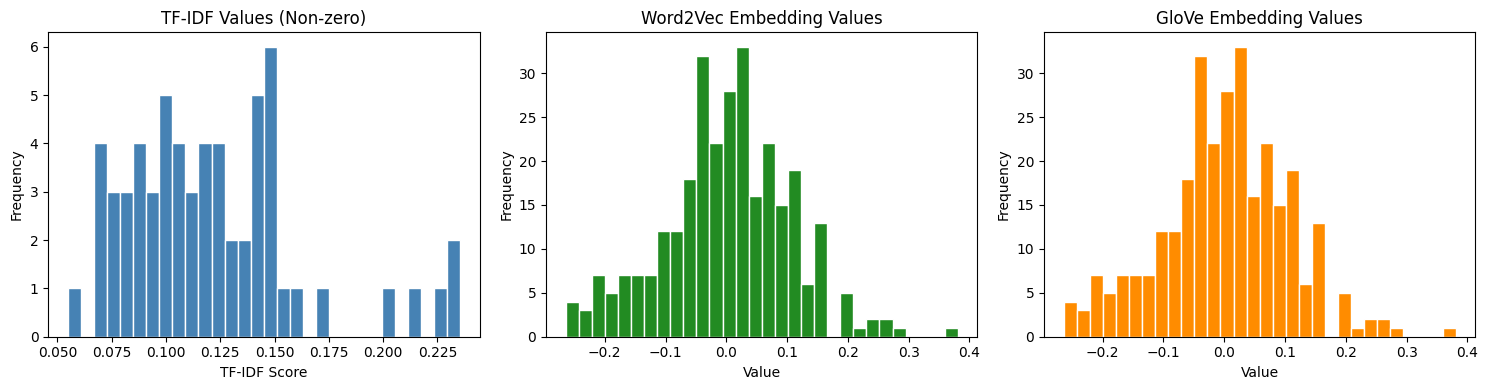

In [24]:
# Visualize embedding dimensions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TF-IDF distribution (sample)
tfidf_sample = X_train_tfidf[0].toarray().flatten()
nonzero_tfidf = tfidf_sample[tfidf_sample > 0]
axes[0].hist(nonzero_tfidf, bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('TF-IDF Values (Non-zero)', fontsize=12)
axes[0].set_xlabel('TF-IDF Score')
axes[0].set_ylabel('Frequency')

# Word2Vec distribution
w2v_sample = X_train_w2v[0]
axes[1].hist(w2v_sample, bins=30, color='forestgreen', edgecolor='white')
axes[1].set_title('Word2Vec Embedding Values', fontsize=12)
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Frequency')

# GloVe distribution
glove_sample = X_train_glove[0]
axes[2].hist(glove_sample, bins=30, color='darkorange', edgecolor='white')
axes[2].set_title('GloVe Embedding Values', fontsize=12)
axes[2].set_xlabel('Value')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('../results/figures/embedding_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Save Embeddings

In [25]:
# Save embeddings and data for model training
print("Saving embeddings and data...")

import scipy.sparse as sp

# Create models directory if needed
os.makedirs('../models/embeddings', exist_ok=True)

# Save TF-IDF
sp.save_npz('../models/embeddings/X_train_tfidf.npz', X_train_tfidf)
sp.save_npz('../models/embeddings/X_test_tfidf.npz', X_test_tfidf)
print("Saved TF-IDF embeddings")

# Save Word2Vec
np.save('../models/embeddings/X_train_w2v.npy', X_train_w2v)
np.save('../models/embeddings/X_test_w2v.npy', X_test_w2v)
print("Saved Word2Vec embeddings")

# Save GloVe
np.save('../models/embeddings/X_train_glove.npy', X_train_glove)
np.save('../models/embeddings/X_test_glove.npy', X_test_glove)
print("Saved GloVe embeddings")

# Save labels
np.save('../models/embeddings/y_train.npy', y_train)
np.save('../models/embeddings/y_test.npy', y_test)
print("Saved labels")

# Save embedding models
tfidf_embedding.save('../models/embeddings/tfidf_model.pkl')
word2vec_embedding.save('../models/embeddings/word2vec_model.pkl')
if glove_embedding:
    glove_embedding.save('../models/embeddings/glove_model.pkl')
print("Saved embedding models")

print("\nAll embeddings saved successfully!")

Saving embeddings and data...
Saved TF-IDF embeddings
Saved Word2Vec embeddings
Saved GloVe embeddings
Saved labels
Saved embedding models

All embeddings saved successfully!


## 8. Summary

### Embedding Characteristics

| Embedding | Dimensionality | Training | Semantics | Best For |
|-----------|---------------|----------|-----------|----------|
| TF-IDF | High (sparse) | Corpus | No | Keyword-based classification |
| Word2Vec | 300 (dense) | Corpus | Yes | Domain-specific semantics |
| GloVe | 100 (dense) | Pre-trained | Yes | General language understanding |

### Next Steps

Proceed to `03_model_training.ipynb` to train and evaluate traditional ML models with these embeddings.

In [26]:
print("="*60)
print("EMBEDDING GENERATION COMPLETE")
print("="*60)
print(f"\nGenerated embeddings:")
print(f"  - TF-IDF: {X_train_tfidf.shape}")
print(f"  - Word2Vec: {X_train_w2v.shape}")
print(f"  - GloVe: {X_train_glove.shape}")
print("\nProceed to notebook 03_model_training.ipynb")

EMBEDDING GENERATION COMPLETE

Generated embeddings:
  - TF-IDF: (40338, 10000)
  - Word2Vec: (40338, 300)
  - GloVe: (40338, 300)

Proceed to notebook 03_model_training.ipynb
